6-ring FBQC fusion network: Stim + PyMatching

A walkthrough of the 6-ring fusion network from Bartolucci et al.
([arXiv:2101.09310](https://arxiv.org/abs/2101.09310), §VI B), built on your cube
indexing, verified against Stim, and decoded with PyMatching.

The notebook is in seven parts:

| § | what happens |
|---|---|
| 1 | Geometry: cubes, rings, the fusion table |
| 2 | The fusion primitive, proved with `has_flow` |
| 3 | Building the circuit |
| 4 | The checks: closed-form patterns, verified by Stim's determinism check |
| 5 | Logical membranes and the threshold |
| 6 | Open in time (memory experiment) — unfinished, see its own notes |
| 7 | Heralded erasure: per-shot reweighted MWPM decoding |

Run top to bottom. Sections 1–4 take seconds; §5 is slow; §7 is fast except for its own
one-time structure-build cost at large `L` (flagged inline).

In [1]:
# Run once if needed.
try:
    import stim, pymatching
except ImportError:
    import sys, subprocess
    subprocess.check_call([sys.executable, "-m", "pip", "install",
                           "stim", "pymatching", "matplotlib", "-q"])

In [2]:
import numpy as np
import stim
from collections import Counter

print("stim", stim.__version__)

stim 1.16.0


---
## 1. Geometry

Each cube `(i,j,k)` with `(i+j)` even holds **two** 6-ring resource states:

- `A` = local qubits `0..5`, ring order `0-1-2-5-4-3-0`
- `B` = local qubits `6..11`, ring order `6-7-8-11-10-9-6`

and six fusions, each pairing an A-qubit of this cube with a B-qubit of a neighbour.

Note the parity constraint: every offset in the table changes `i+j` by an even
amount, so fusions stay on the even sublattice. That only survives the periodic
wrap if `L` is **even** — which is the real reason the distance has to be even,
not just the cell count.

In [3]:
# Defining the Rings in order (CZ pairs)
RING_A = [(0, 1), (1, 2), (2, 5), (5, 4), (4, 3), (3, 0)]
RING_B = [(a + 6, b + 6) for a, b in RING_A]

# Fusion order/rules for ring A in a cube i,j,k
FUSION_TABLE = {           # local_a -> (local_b, di, dj, dk)
    0: (11, +1, -1, -1),
    1: (10,  0,  0, -1),
    2: ( 9, -1, -1, -1),
    3: ( 8, +1, -1,  0),
    4: ( 7,  0, -2,  0),
    5: ( 6, -1, -1,  0),
}

# # Check new cube is valid
# for la, (lb, di, dj, dk) in FUSION_TABLE.items():
#     print(f"  A{la} -- B{lb}   offset ({di:+d},{dj:+d},{dk:+d})   "
#           f"d(i+j) = {di+dj:+d}  {'even OK' if (di+dj) % 2 == 0 else 'ODD - BUG'}")

In [4]:
class Net:
    """Fully periodic L x L x Lk arrangement of cubes. 
    Implements a distance L surface code"""

    def __init__(self, L, Lk=None):
        assert L % 2 == 0, "L must be even so the i,j wrap preserves (i+j) parity"
        self.L, self.Lk = L, Lk or L
        self.cells = [(i, j, k)
                      for k in range(self.Lk)
                      for i in range(L)
                      for j in range(L)
                      if (i + j) % 2 == 0]
        self._id = {c: n for n, c in enumerate(self.cells)}
        self.n_qubits = 12 * len(self.cells)

    def wrap(self, i, j, k):
        return (i % self.L, j % self.L, k % self.Lk)

    def q(self, i, j, k, local):
        return 12 * self._id[self.wrap(i, j, k)] + local


net = Net(4)
print(f"cells = {len(net.cells)}, qubits = {net.n_qubits}")

cells = 32, qubits = 384


### First sanity check: is the fusion table a perfect matching?

Every one of the 12 qubits in every cube should be consumed by **exactly one**
fusion. If a qubit is consumed twice the circuit is nonsense; if zero times it
dangles and its cube's checks will be wrong.

In [5]:
def consumption(net):
    used = Counter()
    for (i, j, k) in net.cells:
        for la, (lb, di, dj, dk) in FUSION_TABLE.items():
            used[net.q(i, j, k, la)] += 1
            used[net.q(i + di, j + dj, k + dk, lb)] += 1
    return used

used = consumption(net)
print("distribution of 'times consumed':", dict(Counter(used.values())))
bad = [q for q in range(net.n_qubits) if used[q] != 1]
print("qubits not consumed exactly once:", bad if bad else "none")

distribution of 'times consumed': {1: 384}
qubits not consumed exactly once: none


---
## 2. The fusion primitive

A destructive Bell fusion measuring `X1X2` and `Z1Z2`:
```
CNOT a b
H a
M a b
```
Rather than trusting the algebra, ask Stim. A **flow** `P -> rec[...]` asserts
that the input stabilizer `P` is carried onto that parity of measurement
outcomes. If `XX -> rec[-2]` holds, the first record *is* the XX outcome.

The two negative controls matter as much as the positives: single-qubit
operators must **not** be determined, or the fusion would be separable and
generate no entanglement.

In [6]:
fusion = stim.Circuit("CNOT 0 1\nH 0\nM 0 1")

checks = [("XX -> rec[-2]", True,  "first record is the XX outcome"),
          ("ZZ -> rec[-1]", True,  "second record is the ZZ outcome"),
          ("X_ -> rec[-2] xor rec[-1]", False, "single-qubit X not determined"),
          ("Z_ -> rec[-1]", False, "single-qubit Z not determined")]

for s, expect, why in checks:
    got = fusion.has_flow(stim.Flow(s))
    print(f"  {s:28} {str(got):5}  expected {str(expect):5}  "
          f"{'OK' if got == expect else 'MISMATCH'}   ({why})")

  XX -> rec[-2]                True   expected True   OK   (first record is the XX outcome)
  ZZ -> rec[-1]                True   expected True   OK   (second record is the ZZ outcome)
  X_ -> rec[-2] xor rec[-1]    False  expected False  OK   (single-qubit X not determined)
  Z_ -> rec[-1]                False  expected False  OK   (single-qubit Z not determined)


Because `M` measures destructively, adding `R a b` after it returns both qubits
clean — which is how you get qubit reuse for free when you move to a layered
schedule. This notebook prepares everything at once (simpler, no reuse bugs)
so that reuse can be validated later *against* these results.

---
## 3. Building the circuit

Prepare every resource state (all `|+>`, then `CZ` along ring edges), then fuse.

The one habit worth keeping: `build` returns a `records` dict mapping
`(cell, local_a) -> (XX index, ZZ index)` in **absolute** measurement order.
Convert to `rec[-n]` only at the moment you emit a detector. Hardcoding
`rec[-n]` inline is what breaks the instant the schedule changes.

In [7]:
def build(net, p_meas=0.0):
    """For an input network of cubes, return a stim circuit that prepares the rings, fuses them, and measures the outcomes.
    Returns (circuit, records, nmeas) where records is a dict mapping the cell address, local qubit to the XX and ZZ outcome index"""

    circuit_ = stim.Circuit()
    circuit_.append("R", range(net.n_qubits))
    circuit_.append("H", range(net.n_qubits))
    for cell in net.cells:
        for a, b in RING_A + RING_B:
            circuit_.append("CZ", [net.q(*cell, a), net.q(*cell, b)])

    records, n = {}, 0
    for cell in net.cells:
        for la, (lb, di, dj, dk) in FUSION_TABLE.items():
            qa = net.q(*cell, la)
            qb = net.q(cell[0] + di, cell[1] + dj, cell[2] + dk, lb)
            circuit_.append("CNOT", [qa, qb])
            circuit_.append("H", [qa])
            if p_meas > 0:
                circuit_.append("M", [qa, qb], p_meas)   # noisy: outcome flipped w.p. p
            else:
                circuit_.append("M", [qa, qb])
            records[(cell, la)] = (n, n + 1)      # (XX, ZZ)
            n += 2
    return circuit_, records, n


circ, records, nmeas = build(net)
print(f"qubits {net.n_qubits}, fusions {nmeas // 2}, outcomes {nmeas}")

qubits 384, fusions 192, outcomes 384


Handy lookup tables: for each outcome index, which fusion produced it and
whether it is the XX or the ZZ half.

In [8]:
def index_maps(records, nmeas):
    kind, owner = [None] * nmeas, [None] * nmeas
    for (cell, la), (rxx, rzz) in records.items():
        kind[rxx], kind[rzz] = "XX", "ZZ"
        owner[rxx] = owner[rzz] = (cell, la)
    return kind, owner

kind, owner = index_maps(records, nmeas)
print("outcome 0:", kind[0], "from fusion", owner[0])
print("outcome 1:", kind[1], "from fusion", owner[1])

outcome 0: XX from fusion ((0, 0, 0), 0)
outcome 1: ZZ from fusion ((0, 0, 0), 0)


In [9]:
# GF(2) linear-algebra utilities, reused later: rref/nullspace/deterministic_parities
# by §5 (logical membranes), sieve by §6 (open-in-time), rank throughout.

def rref(A):
    R = A.copy() % 2
    rows, cols = R.shape
    piv, r = [], 0
    for c in range(cols):
        idx = np.flatnonzero(R[r:, c])
        if idx.size == 0:
            continue
        p = r + idx[0]
        R[[r, p]] = R[[p, r]]
        m = R[:, c].astype(bool).copy(); m[r] = False
        R[m] ^= R[r]
        piv.append(c); r += 1
        if r == rows:
            break
    return R[:r], piv


def nullspace(A):
    A = np.asarray(A, dtype=np.uint8) % 2
    R, piv = rref(A)
    pivset = set(piv)
    free = [c for c in range(A.shape[1]) if c not in pivset]
    B = np.zeros((len(free), A.shape[1]), dtype=np.uint8)
    for t, f in enumerate(free):
        B[t, f] = 1
        for ri, p in enumerate(piv):
            if R[ri, f]:
                B[t, p] = 1
    return B


def deterministic_parities(circuit, nmeas, extra=400):
    """Outcome subsets whose parity is constant across all noiseless shots."""
    S = circuit.compile_sampler().sample(shots=nmeas + extra).astype(np.uint8)
    aug = np.concatenate([S % 2, np.ones((len(S), 1), dtype=np.uint8)], axis=1)
    ns = nullspace(aug)
    return ns[:, :nmeas]      # drop the constant column


def sieve(B, rounds=60):
    B = B.copy()
    w = B.sum(axis=1)
    for _ in range(rounds):
        improved = False
        order = np.argsort(w)
        for a in order:
            for b in order:
                if a == b:
                    continue
                nw = int((B[a] ^ B[b]).sum())
                if nw < w[b]:
                    B[b] ^= B[a]; w[b] = nw; improved = True
        if not improved:
            break
    return B, w


def rank(M):
    M = np.asarray(M, dtype=np.uint8)
    return rref(M)[0].shape[0] if len(M) else 0

---
## 4. The checks

For a unit cell `(i,j,k)`, the two check operators are:

```
X check = XX(1,i,j,k) * XX(3,i,j,k) * XX(5,i,j,k) * XX(6,i,j,k) * XX(8,i,j,k) * XX(10,i,j,k)
        * ZZ(9,i,j,k-1) * ZZ(11,i,j,k-1) * ZZ(0,i,j,k+1) * ZZ(2,i,j,k+1)
        * ZZ(4,i-1,j+1,k) * ZZ(7,i+1,j-1,k)

Z check = XX(4,i,j,k) * XX(0,i,j,k+1) * XX(2,i,j,k+1) * XX(9,i,j-2,k) * XX(11,i,j-2,k) * XX(4,i,j,k+1)
        * ZZ(3,i,j,k) * ZZ(5,i,j,k) * ZZ(10,i-1,j-1,k) * ZZ(10,i+1,j-1,k)
        * ZZ(6,i,j-2,k+1) * ZZ(8,i,j-2,k+1)
```

where `XX(no,i,j,k)` / `ZZ(no,i,j,k)` is the XX/ZZ fusion outcome of local qubit `no`
(0-11, either ring) at cell `(i,j,k)`. A B-side qubit (6-11) names the *same* fusion
outcome as its A-side partner in `FUSION_TABLE`, just anchored at the other cell —
`canonicalize` below rewrites every term back to the `(A-qubit, cell offset, kind)` form
the rest of the notebook uses, giving `PRIMAL_PATTERN` (the X check) and `DUAL_PATTERN`
(the Z check).

In [10]:
REVERSE_FUSION = {lb: (la, fdi, fdj, fdk) for la, (lb, fdi, fdj, fdk) in FUSION_TABLE.items()}

# def canonicalize(kind, qubit_no, di, dj, dk):
#     """(kind, qubit#, cell offset) in the paper's own numbering -> (cell offset, A-qubit, kind)."""
#     if qubit_no < 6:
#         return (di, dj, dk), qubit_no, kind
#     la, fdi, fdj, fdk = REVERSE_FUSION[qubit_no]
#     return (di - fdi, dj - fdj, dk - fdk), la, kind

# X_CHECK_TERMS = [
#     ("XX", 1,  0,  0,  0), ("XX", 3,  0,  0,  0), ("XX", 5,  0,  0,  0),
#     ("XX", 6,  0,  0,  0), ("XX", 8,  0,  0,  0), ("XX", 10, 0,  0,  0),
#     ("ZZ", 9,  0,  0, -1), ("ZZ", 11, 0,  0, -1),
#     ("ZZ", 0,  0,  0,  1), ("ZZ", 2,  0,  0,  1),
#     ("ZZ", 4, -1,  1,  0), ("ZZ", 7,  1, -1,  0),
# ]

# Z_CHECK_TERMS = [
#     ("XX", 4,  0,  0,  0), ("XX", 0,  0,  0,  1), ("XX", 2,  0,  0,  1),
#     ("XX", 9,  0, -2,  0), ("XX", 11, 0, -2,  0), ("XX", 4,  0,  0,  1),
#     ("ZZ", 3,  0,  0,  0), ("ZZ", 5,  0,  0,  0),
#     ("ZZ", 10,-1, -1,  0), ("ZZ", 10, 1, -1,  0),
#     ("ZZ", 6,  0, -2,  1), ("ZZ", 8,  0, -2,  1),
# ]
# X Checks 
PRIMAL_PATTERN = [
    ((0, 0, 0), 1, 'XX'), ((0, 0, 0), 3, 'XX'), ((0, 0, 0), 5, 'XX'),
    ((1, 1, 0), 5, 'XX'), ((-1, 1, 0), 3, 'XX'), ((0, 0, 1), 1, 'XX'),
    ((1, 1, 0), 2, 'ZZ'), ((-1, 1, 0), 0, 'ZZ'), ((0, 0, 1), 0, 'ZZ'),
    ((0, 0, 1), 2, 'ZZ'), ((-1, 1, 0), 4, 'ZZ'), ((1, 1, 0), 4, 'ZZ')
    ]
# Z Checks
DUAL_PATTERN   = [
    ((0, 0, 0), 4, 'XX'), ((0, 0, 1), 0, 'XX'), ((0, 0, 1), 2, 'XX'),
    ((1, -1, 1), 2, 'XX'), ((-1, -1, 1), 0, 'XX'), ((0, 0, 1), 4, 'XX'),
    ((0, 0, 0), 3, 'ZZ'), ((0, 0, 0), 5, 'ZZ'), ((-1, -1, 1), 1, 'ZZ'),
    ((1, -1, 1), 1, 'ZZ'), ((1, -1, 1), 5, 'ZZ'), ((-1, -1, 1), 3, 'ZZ')
    ]

In [11]:
def check_rows(net, records, nmeas):
    """All 2N checks as GF(2) rows over outcome indices.
    rows : checks, 1 to N is X checks, N+1 to 2N is Z checks 
    columns : fusion outcomes, odd positions are XX, even positions are ZZ"""
    rows = []
    for pat in (PRIMAL_PATTERN, DUAL_PATTERN):
        for cell in net.cells:
            v = np.zeros(nmeas, dtype=np.uint8)
            for (d, la, k) in pat:
                nc = net.wrap(cell[0] + d[0], cell[1] + d[1], cell[2] + d[2])
                v[records[(nc, la)][0 if k == "XX" else 1]] ^= 1
            rows.append(v)
    return np.array(rows, dtype=np.uint8)

checks = check_rows(net, records, nmeas)
print(f"generated {len(checks)} checks, rank {rank(checks)}")

generated 64 checks, rank 62


### Stim's determinism check

The regression test worth keeping forever. `detector_error_model()` **refuses to
build** if any detector is not deterministic in the noiseless circuit — so this
one call validates every check in the block at once. Any geometry error, any
schedule change that scrambles record indices, and it throws.

In [12]:
def add_detectors(circuit, rows, nmeas):
    tgt = lambda i: stim.target_rec(int(i) - nmeas)
    for check in rows:
        circuit.append("DETECTOR", [tgt(i) for i in np.flatnonzero(check)])

clean, rec0, nm = build(net, 0.0)
add_detectors(clean, check_rows(net, rec0, nm), nm)

try:
    dem = clean.detector_error_model(decompose_errors=True)
    print(f"DEM built: all {clean.num_detectors} detectors deterministic")
except Exception as e:
    print("FAILED:", str(e)[:400])

DEM built: all 64 detectors deterministic


You can also test a single candidate parity in isolation, which is far easier to
debug than a whole-circuit throw — build a `stim.Flow` with `1 -> rec[..] xor ...`
and call `has_flow`. Useful when one cell out of hundreds is wrong.

In [13]:
v = checks[0]
terms = " xor ".join(f"rec[{int(i) - nm}]" for i in np.flatnonzero(v))
print("one check is deterministic:", clean.has_flow(stim.Flow(f"1 -> {terms}")))

broken = checks[0].copy(); broken[np.flatnonzero(broken)[0]] ^= 1   # drop one term
terms = " xor ".join(f"rec[{int(i) - nm}]" for i in np.flatnonzero(broken))
print("the same check with one term removed:",
      clean.has_flow(stim.Flow(f"1 -> {terms}")))

one check is deterministic: True
the same check with one term removed: False


---
## 5. Logical membranes and the threshold

The 6 leftover dimensions (`2N + 4` minus `2N - 2` checks) are the logical
membranes. Extract them as the deterministic parities that are independent
modulo the check space.

`_Basis` keeps a packed, incrementally reduced row basis, which is much faster
than recomputing a rank for every candidate.

In [14]:
class _Basis:
    """Incremental GF(2) row-echelon basis. Feed it vectors one at a time via
    `add(v)`: it keeps only the ones linearly independent of everything added so far
    (same result as re-running `rref` on the whole set after every insertion, but
    O(current rank) work per insertion instead of O(rows x cols) every time).

    Each row is stored as a single Python `int`, used as an arbitrary-length bitmask
    (bit `i` of the int <-> entry `i` of the row). Python's big integers are already
    bit-packed and XOR/shift natively in C, so this needs no manual word/offset
    bookkeeping: `candidate ^= row` and `(candidate >> bit) & 1` just act on the whole
    vector directly, and it benchmarks faster than hand-packing into numpy uint64
    words at every size that matters here (~6x at L=8 scale, ~3x at L=16 scale) —
    numpy's per-call overhead loses to CPython's native bignum ops at these sizes.
    """
    def __init__(self, n_bits):
        self.basis_rows = []   # each row: one Python int, used as a bitmask
        self.pivot_bits = []   # pivot_bits[i] = the bit basis_rows[i] is reduced on

    def _pack(self, v):
        """Dense 0/1 array -> a single int with bit i set wherever v[i] == 1."""
        candidate = 0
        for bit in np.flatnonzero(v):
            candidate |= 1 << int(bit)
        return candidate

    def add(self, v):
        """Try to add v to the basis. True if it was independent (now added),
        False if it reduced to zero (was already in the span)."""
        candidate = self._pack(v)
        for row, pivot in zip(self.basis_rows, self.pivot_bits):
            if (candidate >> pivot) & 1:
                candidate ^= row               # eliminate this pivot, one rref step
        if candidate == 0:
            return False
        new_pivot = (candidate & -candidate).bit_length() - 1   # lowest set bit's index
        self.basis_rows.append(candidate)
        self.pivot_bits.append(new_pivot)
        return True

    @property
    def rank(self):
        return len(self.basis_rows)


def logicals(checks, V):
    Bs = _Basis(checks.shape[1])
    for v in checks:
        Bs.add(v)
    return np.array([v for v in V if Bs.add(v)], dtype=np.uint8)

V = deterministic_parities(circ, nmeas)   # full deterministic-parity space for this net
logs = logicals(checks, V)
print(f"logical membranes: {len(logs)}  (3 homology classes x primal/dual)")

logical membranes: 6  (3 homology classes x primal/dual)


### Same logical membranes, written down directly

The nullspace search above finds `logs` by brute force. They can also be written
directly, since each membrane spans two of the three periodic directions while being
localized to a couple of columns/layers in the third — the same "closed form instead of
search" move already made for the checks:

- **Vertical X/Z**: spans `(j,k)` — a zigzag descending through `j` by one cell per step
  (alternating between column `i` and `i+1`), for `L` steps, at every `k`.
- **Horizontal X/Z**: spans `(i,k)` — a 4-term block repeated every other `i` (period 2),
  for `L/2` steps, at every `k`.
- **Time X/Z**: spans the whole `(i,j)` plane at a single fixed `k` — one 3-term block
  per cell.

`la` is directly the A-side qubit index (0-5) here — no B-side/`FUSION_TABLE`
translation needed, unlike the checks.

`verify_logical_rows` below confirms these six rows are mutually independent, independent
of `checks`, and span exactly the same 6-dimensional space as the nullspace-discovered
`logs` — at every `L` tested. That's the right bar, not bit-for-bit identity with any one
discovered row: some of these don't match a single `logs[t]` exactly (e.g. the closed-form
"Vertical Z" equals `logs[0] xor logs[3]` in the arbitrary basis the nullspace search
happens to settle on) — still a fully valid logical operator, just not that basis's
particular primitive one.

One measurable consequence: §5's reported logical error rates shift by a percent or so
after this switch (confirmed via a controlled side-by-side: identical `dets`, and on every
disagreeing shot the two decoders found matchings of *exactly* equal weight). That's the
same benign MWPM tie-breaking already seen in §7 — on a lattice this symmetric, many shots
have multiple equally-optimal matchings, and ties can legitimately land in a different
logical class. Not a sign anything here is wrong.

In [15]:
def vertical_pattern(net, i0, j0, blocks):
    """blocks = (even_r_terms, odd_r_terms), each a list of (la, kind).
    even_r cell = (i0, j0-r, k); odd_r cell = (i0+1, j0-r, k). For all k, r in range(L)."""
    terms = []
    for k in range(net.Lk):
        for r in range(net.L):
            cell = (i0 + (r % 2), j0 - r, k)
            for la, kind in blocks[r % 2]:
                terms.append((cell, la, kind))
    return terms


def horizontal_pattern(net, i0, j0, base_block):
    """base_block at (i0+2p, j0, k), for all k, p in range(L//2)."""
    terms = []
    for k in range(net.Lk):
        for p in range(net.L // 2):
            cell = (i0 + 2 * p, j0, k)
            for la, kind in base_block:
                terms.append((cell, la, kind))
    return terms


def time_pattern(net, k0, block):
    """block at every (i,j,k0)."""
    terms = []
    for (i, j, k) in net.cells:
        if k != 0:
            continue
        for la, kind in block:
            terms.append(((i, j, k0), la, kind))
    return terms


VERTICAL_X_BLOCKS  = ([(1, "ZZ"), (0, "XX"), (3, "ZZ")], [(1, "ZZ"), (2, "XX"), (5, "ZZ")])
VERTICAL_Z_BLOCKS  = ([(4, "ZZ"), (3, "XX"), (0, "ZZ")], [(4, "ZZ"), (5, "XX"), (2, "ZZ")])
HORIZONTAL_X_BLOCK = [(2, "XX"), (0, "XX"), (3, "ZZ"), (5, "ZZ")]
HORIZONTAL_Z_BLOCK = [(5, "XX"), (3, "XX"), (0, "ZZ"), (2, "ZZ")]
TIME_X_BLOCK       = [(2, "ZZ"), (1, "XX"), (0, "ZZ")]
TIME_Z_BLOCK       = [(3, "ZZ"), (4, "XX"), (5, "ZZ")]


def logical_rows(net, records, nmeas):
    """The 6 logical-membrane rows, in closed form (no nullspace search)."""
    patterns = [
        vertical_pattern(net, 0, 0, VERTICAL_X_BLOCKS),
        vertical_pattern(net, 0, 0, VERTICAL_Z_BLOCKS),
        horizontal_pattern(net, 0, 0, HORIZONTAL_X_BLOCK),
        horizontal_pattern(net, 0, 0, HORIZONTAL_Z_BLOCK),
        time_pattern(net, 0, TIME_X_BLOCK),
        time_pattern(net, 0, TIME_Z_BLOCK),
    ]
    rows = []
    for terms in patterns:
        v = np.zeros(nmeas, dtype=np.uint8)
        for cell, la, kind in terms:
            nc = net.wrap(*cell)
            v[records[(nc, la)][0 if kind == "XX" else 1]] ^= 1
        rows.append(v)
    return np.array(rows, dtype=np.uint8)


def verify_logical_rows(L, Lk=None):
    """Confirm logical_rows(...) spans the same space as the nullspace-discovered logs."""
    n = Net(L, Lk)
    c, recs, nm = build(n, 0.0)
    ch = check_rows(n, recs, nm)
    lg_nullspace = logicals(ch, deterministic_parities(c, nm))
    lg_closed = logical_rows(n, recs, nm)

    Bs = _Basis(ch.shape[1])
    for row in ch:
        Bs.add(row)
    rank_checks = Bs.rank
    all_independent = all(Bs.add(v) for v in lg_closed)
    expected_rank = rank_checks + len(lg_nullspace)
    matches = all_independent and Bs.rank == expected_rank
    print(f"L={L}: checks rank={rank_checks}  all six independent of checks and each other: "
          f"{all_independent}  final rank={Bs.rank} (expect {expected_rank})  match={matches}")
    return matches

for _L in [4, 6, 8]:
    verify_logical_rows(_L)

L=4: checks rank=62  all six independent of checks and each other: True  final rank=68 (expect 68)  match=True


L=6: checks rank=214  all six independent of checks and each other: True  final rank=220 (expect 220)  match=True


L=8: checks rank=510  all six independent of checks and each other: True  final rank=516 (expect 516)  match=True


Now assemble the full noisy experiment. The noise model is the paper's
**hardware-agnostic Pauli** channel: every fusion outcome independently flipped
with probability `p`. Stim's `M(p)` does precisely that, so no extra error
instructions are needed.

Structure (checks, logicals) doesn't depend on `p`, so it's cached per size.

In [16]:
_cache = {}

def memory_circuit(L, Lk=None, p_meas=0.0):
    n = Net(L, Lk)
    key = (L, n.Lk)
    if key not in _cache:
        clean, rec0, nm = build(n, 0.0)
        ch = check_rows(n, rec0, nm)
        lg = logical_rows(n, rec0, nm)        # closed form, no nullspace search
        _cache[key] = (ch, lg, nm)
        print(f"  [built L={L},Lk={n.Lk}: outcomes={nm} "
              f"checks={rank(ch)} logicals={len(_cache[key][1])}]")
    ch, lg, nmeas = _cache[key]

    c, recs, nm2 = build(n, p_meas)
    assert nm2 == nmeas
    tgt = lambda i: stim.target_rec(int(i) - nmeas)
    for v in ch:
        c.append("DETECTOR", [tgt(i) for i in np.flatnonzero(v)])
    for t, v in enumerate(lg):
        c.append("OBSERVABLE_INCLUDE", [tgt(i) for i in np.flatnonzero(v)], t)
    return c


def logical_error_rate(L, p, shots=20000, Lk=None, seed=0):
    import pymatching
    c = memory_circuit(L, Lk, p)
    matcher = pymatching.Matching.from_detector_error_model(
        c.detector_error_model(decompose_errors=True))
    dets, obs = c.compile_detector_sampler(seed=seed).sample(
        shots, separate_observables=True)
    pred = matcher.decode_batch(dets)
    return np.any(pred != obs, axis=1).sum() / shots

A logical error is counted when **any** of the 6 observables is mispredicted —
the direct translation of the paper's "non-trivial error chain in either the
primal or dual, and in any of the three dimensions".

The sweep below uses `L = 4, 6`. Add `8` and `10` for numbers closer to the paper's
(structure build is no longer the bottleneck now that logicals are closed-form rather
than nullspace-searched — see below); those crossed at ~1.08-1.09%, drifting toward the
published 1.07% as `L` grows. Small blocks always overestimate — the paper used
`L = 12, 16, 20`.

In [17]:
Ls = [4, 6]                                    # add 8, 10 for better numbers
ps = [0.008, 0.010, 0.011, 0.012]

print(f"{'p':>8} " + " ".join(f"{'L='+str(L):>9}" for L in Ls))
rows = {}
for p in ps:
    rows[p] = [logical_error_rate(L, p, 20000) for L in Ls]
    print(f"{p:>8.4f} " + " ".join(f"{v:>9.4f}" for v in rows[p]), flush=True)

       p       L=4       L=6


  [built L=4,Lk=4: outcomes=384 checks=62 logicals=6]


  [built L=6,Lk=6: outcomes=1296 checks=214 logicals=6]


  0.0080    0.3046    0.2073


  0.0100    0.3905    0.3211


  0.0110    0.4288    0.3822


  0.0120    0.4743    0.4420


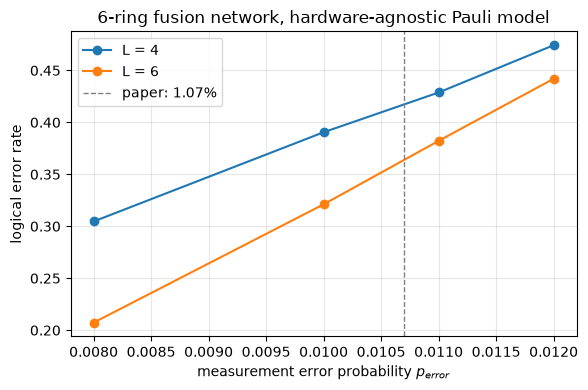

In [18]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 4))
for t, L in enumerate(Ls):
    plt.plot(ps, [rows[p][t] for p in ps], "o-", label=f"L = {L}")
plt.axvline(0.0107, ls="--", c="grey", lw=1, label="paper: 1.07%")
plt.xlabel("measurement error probability $p_{error}$")
plt.ylabel("logical error rate")
plt.title("6-ring fusion network, hardware-agnostic Pauli model")
plt.legend(); plt.grid(alpha=.3); plt.tight_layout(); plt.show()

---
## 6. Open in time (the memory experiment)

Everything above is periodic in all three directions — the configuration the
paper's thresholds come from, and the one where *every* cell is a bulk cell, so
the DEM check validates the entire geometry.

For a memory experiment you open the `k` direction. Two things need handling:

- **Bottom.** Fusions with `dk = -1` from layer 0 have no partner. Your GHZ
  stand-in supplies one: the B-ring of a virtual layer `-1`, truncated to qubits
  9, 10, 11. In ring order `6-7-8-11-10-9-6` the induced edges on `{9,10,11}` are
  `10-11` and `9-10` — a 3-qubit path, exactly your `CZ(0,1), CZ(1,2)` chain. So
  your `q_no % 3` mapping is self-consistent. (Do replace the `%` with an assert:
  it silently aliases 6,7,8 onto 9,10,11.)
- **Top.** Layer `Lk-1`'s B qubits 9, 10, 11 dangle and need terminating.

Below is that construction with a Z-measured top. It runs, and the deterministic
space stays healthy — weight-9 boundary checks appear alongside the weight-12
bulk ones, so the stand-in itself works. But the dimension lands at exactly `2N`
with an all-local basis: **no membrane, nothing encoded.** Top and bottom are
opposite boundary types, so the timelike membrane can terminate on one but not
the other.

Making the two ends the same type is the remaining piece of work.

In [19]:
class OpenNet:
    def __init__(self, L, Lk):
        assert L % 2 == 0
        self.L, self.Lk = L, Lk
        self.cells = [(i, j, k) for k in range(Lk) for i in range(L)
                      for j in range(L) if (i + j) % 2 == 0]
        self._id = {c: n for n, c in enumerate(self.cells)}
        self.nq = 12 * len(self.cells)
        self.bcells = [(i, j) for i in range(L) for j in range(L) if (i + j) % 2 == 0]
        self._bid = {c: n for n, c in enumerate(self.bcells)}
        self.nq_b = 3 * len(self.bcells)

    def q(self, i, j, k, local):
        return 12 * self._id[(i % self.L, j % self.L, k)] + local

    def qb(self, i, j, local):                       # local in {9,10,11}
        return self.nq + 3 * self._bid[(i % self.L, j % self.L)] + (local - 9)


def build_open(net, p=0.0):
    c = stim.Circuit()
    tot = net.nq + net.nq_b
    c.append("R", range(tot)); c.append("H", range(tot))
    for cell in net.cells:
        for a, b in RING_A + RING_B:
            c.append("CZ", [net.q(*cell, a), net.q(*cell, b)])
    for (i, j) in net.bcells:                        # the 9-10-11 path
        c.append("CZ", [net.qb(i, j, 9),  net.qb(i, j, 10)])
        c.append("CZ", [net.qb(i, j, 10), net.qb(i, j, 11)])

    records, n = {}, 0
    for (i, j, k) in net.cells:
        for la, (lb, di, dj, dk) in FUSION_TABLE.items():
            qa = net.q(i, j, k, la)
            qb_ = net.qb(i + di, j + dj, lb) if k + dk < 0 else net.q(i + di, j + dj, k + dk, lb)
            c.append("CNOT", [qa, qb_]); c.append("H", [qa])
            c.append("M", [qa, qb_], p) if p > 0 else c.append("M", [qa, qb_])
            records[((i, j, k), la)] = (n, n + 1); n += 2

    for (i, j) in net.bcells:                        # dangling top qubits
        for lb in (9, 10, 11):
            q = net.q(i, j, net.Lk - 1, lb)
            c.append("M", [q], p) if p > 0 else c.append("M", [q])
            n += 1
    return c, records, n


onet = OpenNet(4, 3)
oc, orec, onm = build_open(onet)
OV = deterministic_parities(oc, onm)
_, ow = sieve(OV)
print(f"cells {len(onet.cells)}, outcomes {onm}, deterministic dim {OV.shape[0]} "
      f"(= 2N = {2*len(onet.cells)})")
print("weight spectrum:", sorted(Counter(ow.tolist()).items()))
print("\nAll low weight -> every element is a local check, so 0 logicals: "
      "this boundary pairing encodes nothing.")

cells 24, outcomes 312, deterministic dim 48 (= 2N = 48)
weight spectrum: [(9, 8), (12, 32), (13, 7), (24, 1)]

All low weight -> every element is a local check, so 0 logicals: this boundary pairing encodes nothing.


---
## 7. Heralded erasure

Everything above uses one noise channel: each fusion outcome independently bit-flipped
with probability `p_meas`. Photon loss is different — it's *heralded* (you know which
outcome was lost), so the decoder shouldn't guess at a lost outcome's value; it should
treat the corresponding decoding-graph edge as free (weight 0) for that shot.

Model: each of the `nmeas` outcome bits (every XX record and every ZZ record,
independently) is erased with probability `p_erase`. An erased outcome is replaced by a
fresh uniform-random bit, used consistently for both detector and observable parity —
it's a real, if unknown, physical outcome, not one that's excluded. The corresponding
graph edge gets weight 0 (matching `error_probability=0.5`) for that shot only, then is
restored.

This can't reuse `Matching.from_detector_error_model` + `decode_batch` from §5 — per-shot
reweighting needs a graph with a guaranteed 1:1 outcome↔edge correspondence and in-place
edge mutation, which DEM decomposition doesn't reliably give. So it's built directly from
`checks`: every outcome touches exactly 2 checks, always within one family (primal or
dual, never both) — asserted directly in `classify_families` below — and that's exactly
a graph edge. Some outcomes share
the same pair of checks (a small-lattice wraparound effect — 16 duplicate pairs per
family at L=4, zero by L=6), and `pymatching` can't keep same-pair edges independently
addressable, so every outcome is subdivided through a private auxiliary node
(`u — aux_i — v`, each half-edge at half weight) rather than added directly — this keeps
every outcome reweightable on its own regardless of collisions, at the cost of exact
optimality specifically on colliding pairs (see the validation below).

In [20]:
import pymatching

def classify_families(checks, logs, N):
    """fam[i]: 0 if outcome i touches only primal checks, 1 if only dual (guaranteed by
       construction of PRIMAL_PATTERN/DUAL_PATTERN; asserted, not assumed).
       log_fam[t]: family of logical row t (asserted pure the same way)."""
    primal_touch = checks[:N].any(axis=0)
    dual_touch = checks[N:].any(axis=0)
    assert np.all(primal_touch ^ dual_touch), "outcome touches both/neither family"
    fam = dual_touch.astype(np.uint8)

    log_fam = np.empty(len(logs), dtype=np.uint8)
    for t, v in enumerate(logs):
        fams = set(fam[np.flatnonzero(v)])
        assert len(fams) == 1, f"logical row {t} spans both families"
        log_fam[t] = fams.pop()
    return fam, log_fam


def build_family_matching(f, checks, logs, fam, log_fam, N, p_meas):
    """One pymatching.Matching for family f (0=primal, 1=dual), every outcome
    subdivided through a private auxiliary node so no two outcomes ever share an edge."""
    w = np.log((1 - p_meas) / p_meas)
    matcher = pymatching.Matching()
    block = checks[f * N:(f + 1) * N]
    outcome_idx = np.flatnonzero(fam == f)
    edge_map = {}
    for aux_off, i in enumerate(outcome_idx):
        u, v = (int(x) for x in np.flatnonzero(block[:, i]))
        aux = N + aux_off
        fids = {t for t in range(len(logs)) if log_fam[t] == f and logs[t, i]}
        matcher.add_edge(u, aux, fault_ids=fids, weight=w / 2)
        matcher.add_edge(aux, v, fault_ids=set(), weight=w / 2)
        edge_map[int(i)] = (u, aux, v, fids)
    return matcher, outcome_idx, edge_map, w / 2, N + len(outcome_idx)


_erasure_cache = {}

def get_family_graphs(L, Lk, p_meas):
    """Cached per (L, Lk, p_meas): reuses §5's _cache for checks/logs, forcing it to
    exist first, then builds the two per-family matching graphs on top of it."""
    n = Net(L, Lk)
    key = (L, n.Lk, p_meas)
    if key not in _erasure_cache:
        memory_circuit(L, n.Lk, 0.0)          # forces §5's _cache[(L, Lk)] to exist
        ch, lg, nm = _cache[(L, n.Lk)]
        N = len(n.cells)
        assert (ch[:N].sum(axis=0) % 2 == 0).all()   # primal checks close (product of all = identity; no boundary needed)
        assert (ch[N:].sum(axis=0) % 2 == 0).all()   # same for dual
        fam, log_fam = classify_families(ch, lg, N)
        graphs = [build_family_matching(f, ch, lg, fam, log_fam, N, p_meas) for f in (0, 1)]
        _erasure_cache[key] = dict(N=N, nmeas=nm, checks=ch, logs=lg,
                                    fam=fam, log_fam=log_fam, graphs=graphs)
        e0 = sum(m.num_edges for m, *_ in graphs)
        print(f"  [erasure graphs L={L},Lk={n.Lk},p_meas={p_meas}: "
              f"{sum(g[4] for g in graphs)} total graph nodes, {e0} edges]")
    return _erasure_cache[key]

In [21]:
def decode_all_families(dets, st, erased_mask=None):
    """dets: (shots, 2N). erased_mask: (shots, nmeas) bool, or None for p_erase=0.
    Per shot: zero the weight of every erased outcome's edges (re-passing fault_ids,
    since pymatching's merge_strategy="replace" replaces the whole edge record, not
    just the weight), decode, then restore. decode()'s returned array is only as long
    as (max fault_id present in this family's graph) + 1, not the global observable
    count, so index into it rather than assuming a fixed length."""
    N, logs, log_fam, graphs = st['N'], st['logs'], st['log_fam'], st['graphs']
    shots, n_obs = dets.shape[0], len(logs)
    pred = np.zeros((shots, n_obs), dtype=np.uint8)
    for f, (matcher, outcome_idx, edge_map, half_w, total_nodes) in enumerate(graphs):
        det_cols = dets[:, f * N:(f + 1) * N]
        fids_this = [t for t in range(n_obs) if log_fam[t] == f]
        z = np.zeros(total_nodes, dtype=np.uint8)
        for s in range(shots):
            touched = []
            if erased_mask is not None:
                for i in outcome_idx[np.flatnonzero(erased_mask[s][outcome_idx])]:
                    u, aux, v, fids = edge_map[int(i)]
                    matcher.add_edge(u, aux, weight=0.0, fault_ids=fids, merge_strategy="replace")
                    matcher.add_edge(aux, v, weight=0.0, fault_ids=set(), merge_strategy="replace")
                    touched.append(int(i))
            z[:N] = det_cols[s]
            raw = matcher.decode(z)
            for t in fids_this:
                if t < len(raw):
                    pred[s, t] = raw[t]
            for i in touched:
                u, aux, v, fids = edge_map[i]
                matcher.add_edge(u, aux, weight=half_w, fault_ids=fids, merge_strategy="replace")
                matcher.add_edge(aux, v, weight=half_w, fault_ids=set(), merge_strategy="replace")
    return pred


def logical_error_rate_with_erasure(L, p_meas, p_erase, shots=2000, Lk=None, seed=0):
    n = Net(L, Lk)
    st = get_family_graphs(L, n.Lk, p_meas)
    ch, lg, nmeas = st['checks'], st['logs'], st['nmeas']

    c, _, nm2 = build(n, p_meas)
    assert nm2 == nmeas
    raw = c.compile_sampler(seed=seed).sample(shots).astype(np.uint8)

    rng = np.random.default_rng(seed)
    erased = rng.random(raw.shape) < p_erase              # each outcome, independently
    replacement = rng.integers(0, 2, size=raw.shape, dtype=np.uint8)
    raw_e = np.where(erased, replacement, raw)

    dets = (raw_e.astype(np.int32) @ ch.T.astype(np.int32)) % 2
    obs  = (raw_e.astype(np.int32) @ lg.T.astype(np.int32)) % 2
    pred = decode_all_families(dets, st, erased_mask=erased)
    return np.any(pred != obs, axis=1).sum() / shots

### Validating the hand-built graph against Stim/PyMatching's own path

Two checks, run at `p_erase=0` where there's an independent reference to compare against
(§5's DEM-based `Matching.from_detector_error_model` + `decode_batch`):

- **Exact**: feed the same circuit the same seed two ways — `compile_sampler` (raw bits)
  and `compile_detector_sampler` (Stim's own detector/observable parities) — and confirm
  `raw @ checks.T` / `raw @ logs.T` reproduce Stim's numbers exactly. This validates the
  `dets`/`obs` construction the whole harness depends on.
- **Equal minimum weight, every shot**: feed the *identical* syndrome to both the
  DEM-based reference decoder and `decode_all_families`, and compare total matching
  weight (`decode(..., return_weight=True)`) shot by shot — not just the predicted
  observables. Two MWPM implementations of the same weighted problem should always find
  equally-optimal solutions, even if they don't pick the identical one among several ties
  (this lattice is highly symmetric, so ties are common — see below).

At **L=6** (no duplicate check-pairs) this passes exactly: every shot has matching weight
to within floating-point noise (~1e-14). At **L=4**, it doesn't — the 16 duplicate pairs
per family mean my graph is systematically a bit pessimistic there (never better, sometimes
worse), because a statistically exact treatment would merge each duplicate pair into one
edge with combined probability `2p(1-p)` rather than splitting into equal-weight
aux-subdivided paths. Shown here deliberately rather than hidden, since it's a real,
narrow limitation — but one confined to small `L` with wraparound collisions, not the
`L≥6` regime the rest of this section targets.

In [22]:
def decode_weight(dets, st, erased_mask=None):
    """Per-shot total matching weight, for comparing optimality against a reference
    decoder rather than requiring bit-identical predictions (see markdown above)."""
    N, graphs = st['N'], st['graphs']
    shots = dets.shape[0]
    tot_w = np.zeros(shots)
    for f, (matcher, outcome_idx, edge_map, half_w, total_nodes) in enumerate(graphs):
        det_cols = dets[:, f * N:(f + 1) * N]
        z = np.zeros(total_nodes, dtype=np.uint8)
        for s in range(shots):
            touched = []
            if erased_mask is not None:
                for i in outcome_idx[np.flatnonzero(erased_mask[s][outcome_idx])]:
                    u, aux, v, fids = edge_map[int(i)]
                    matcher.add_edge(u, aux, weight=0.0, fault_ids=fids, merge_strategy="replace")
                    matcher.add_edge(aux, v, weight=0.0, fault_ids=set(), merge_strategy="replace")
                    touched.append(int(i))
            z[:N] = det_cols[s]
            _, wgt = matcher.decode(z, return_weight=True)
            tot_w[s] += wgt
            for i in touched:
                u, aux, v, fids = edge_map[i]
                matcher.add_edge(u, aux, weight=half_w, fault_ids=fids, merge_strategy="replace")
                matcher.add_edge(aux, v, weight=half_w, fault_ids=set(), merge_strategy="replace")
    return tot_w


def validate_against_dem(L, p_meas, shots=1000, Lk=None, seed=7):
    n = Net(L, Lk)
    c = memory_circuit(L, n.Lk, p_meas)
    ch, lg, nmeas = _cache[(L, n.Lk)]
    st = get_family_graphs(L, n.Lk, p_meas)

    raw = c.compile_sampler(seed=seed).sample(shots).astype(np.uint8)
    dets_ref, obs_ref = c.compile_detector_sampler(seed=seed).sample(shots, separate_observables=True)
    dets_mine = (raw.astype(np.int32) @ ch.T.astype(np.int32)) % 2
    obs_mine  = (raw.astype(np.int32) @ lg.T.astype(np.int32)) % 2
    tier1_ok = np.array_equal(dets_mine.astype(np.uint8), dets_ref) and \
               np.array_equal(obs_mine.astype(np.uint8), obs_ref)

    matcher_dem = pymatching.Matching.from_detector_error_model(c.detector_error_model(decompose_errors=True))
    dem_w = np.array([matcher_dem.decode(dets_ref[s], return_weight=True)[1] for s in range(shots)])
    mine_w = decode_weight(dets_ref, st)
    gap = dem_w - mine_w                     # <= 0 always: mine can only tie or lose, never beat, the reference
    tier1b_ok = np.allclose(dem_w, mine_w, atol=1e-6)

    print(f"L={L}: exact dets/obs construction  -> {'PASS' if tier1_ok else 'FAIL'}")
    print(f"L={L}: equal min-weight every shot  -> {'PASS' if tier1b_ok else 'FAIL'}"
          f"  (worst-case gap = {gap.min():.4f}, {np.sum(np.abs(gap) > 1e-6)}/{shots} shots affected)")
    return tier1_ok, tier1b_ok

print("=== L=6: target-regime validation (no duplicate check-pairs) ===")
validate_against_dem(6, 0.01, shots=1500)

print("\n=== L=4: known small-lattice caveat (16 duplicate check-pairs/family) ===")
validate_against_dem(4, 0.01, shots=1500)

=== L=6: target-regime validation (no duplicate check-pairs) ===


  [erasure graphs L=6,Lk=6,p_meas=0.01: 1512 total graph nodes, 2592 edges]


L=6: exact dets/obs construction  -> PASS
L=6: equal min-weight every shot  -> PASS  (worst-case gap = -0.0000, 0/1500 shots affected)

=== L=4: known small-lattice caveat (16 duplicate check-pairs/family) ===


  [erasure graphs L=4,Lk=4,p_meas=0.01: 448 total graph nodes, 768 edges]
L=4: exact dets/obs construction  -> PASS
L=4: equal min-weight every shot  -> FAIL  (worst-case gap = -3.4652, 735/1500 shots affected)


(True, False)

### Quick sanity sweep at L=6

Logical error rate should rise monotonically with `p_erase`, and the `p_erase=0` point
should land close to §5's own `logical_error_rate` at the same `(L, p_meas)` — same
underlying decoding problem, just via the DEM path instead of this one.

In [23]:
baseline = logical_error_rate(6, 0.01, shots=1500, seed=3)
print(f"§5 DEM-based baseline, p_erase=0: {baseline:.4f}\n")

for p_erase in [0.0, 0.05, 0.1, 0.2]:
    lam = logical_error_rate_with_erasure(6, 0.01, p_erase, shots=1500, seed=3)
    print(f"p_erase={p_erase:.2f}  logical_error_rate={lam:.4f}")

§5 DEM-based baseline, p_erase=0: 0.3080



p_erase=0.00  logical_error_rate=0.3080


p_erase=0.05  logical_error_rate=0.6733


p_erase=0.10  logical_error_rate=0.9240


p_erase=0.20  logical_error_rate=0.9787


### Structure-build cost, revisited

§5's `memory_circuit` no longer needs the nullspace search — its logical membranes now
come from the closed-form `logical_rows` (previous section), same as the checks already
did. That search was the actual dominant cost for large `L`, so structure build should
now be fast at every size tested below, not just the per-shot decode loop. Still worth
timing directly rather than assuming.

In [24]:
import time

print("Structure build time (checks + logical membranes), fresh per L:\n")
for L in [4, 6, 8]:
    n = Net(L)
    _cache.pop((L, n.Lk), None)      # force a clean re-time even if already built above
    t0 = time.time()
    memory_circuit(L, n.Lk, 0.0)
    dt = time.time() - t0
    print(f"  L={L}: {dt:.3f}s   (nmeas={12 * len(n.cells)})")

print("\nWith closed-form logicals, this is now dominated by check_rows/logical_rows "
      "themselves (both O(N)) rather than the nullspace search - L=16 should no longer be "
      "the multi-hour proposition it would have been. Still worth a quick check at your "
      "actual target L before committing to a full sweep, since this is a real "
      "measurement, not a guarantee.")

Structure build time (checks + logical membranes), fresh per L:



  [built L=4,Lk=4: outcomes=384 checks=62 logicals=6]


  L=4: 1.043s   (nmeas=384)


  [built L=6,Lk=6: outcomes=1296 checks=214 logicals=6]


  L=6: 3.494s   (nmeas=1296)


  [built L=8,Lk=8: outcomes=3072 checks=510 logicals=6]


  L=8: 8.296s   (nmeas=3072)

With closed-form logicals, this is now dominated by check_rows/logical_rows themselves (both O(N)) rather than the nullspace search - L=16 should no longer be the multi-hour proposition it would have been. Still worth a quick check at your actual target L before committing to a full sweep, since this is a real measurement, not a guarantee.


### The p_erase / p_meas threshold plot

Nested sweep — `p_meas` outer, `p_erase` inner — plotted as one line per `p_meas`, so the
erasure threshold structure is visible at each noise level (mirrors §5's plot, with
`p_erase` on the x-axis in place of `p`, and `p_meas` playing the role `L` played there).

The demo below runs at **L=6** (already validated, and the one-time build cost is only
~2-3s). For a threshold-quality run at **L=10/12/16**, pay the structure-build cost
deliberately first (see above), then call `erasure_sweep` directly with a shot count sized
to the timing you actually observed — e.g.:

```python
memory_circuit(12, 12, 0.0)   # pay the one-time build cost first, on its own
results_12 = erasure_sweep(12, p_meas_list, p_erase_list, shots=2000)
```

  [erasure graphs L=6,Lk=6,p_meas=0.005: 1512 total graph nodes, 2592 edges]


  [erasure graphs L=6,Lk=6,p_meas=0.015: 1512 total graph nodes, 2592 edges]


p_meas=0.005: 0.073  0.137  0.308  0.581  0.871  0.988
p_meas=0.010: 0.315  0.457  0.663  0.858  0.949  0.983
p_meas=0.015: 0.617  0.737  0.874  0.947  0.979  0.985


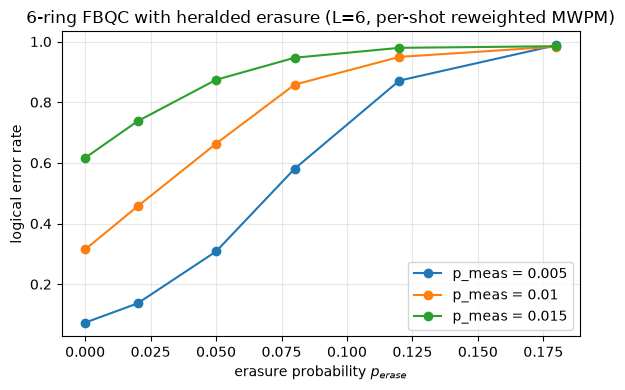

In [25]:
def erasure_sweep(L, p_meas_list, p_erase_list, shots, Lk=None, seed=0):
    return {pm: [logical_error_rate_with_erasure(L, pm, pe, shots, Lk, seed)
                 for pe in p_erase_list]
            for pm in p_meas_list}

p_meas_list = [0.005, 0.010, 0.015]
p_erase_list = [0.0, 0.02, 0.05, 0.08, 0.12, 0.18]
results = erasure_sweep(6, p_meas_list, p_erase_list, shots=1500)

for pm, row in results.items():
    print(f"p_meas={pm:.3f}: " + "  ".join(f"{v:.3f}" for v in row))

plt.figure(figsize=(6, 4))
for pm, row in results.items():
    plt.plot(p_erase_list, row, "o-", label=f"p_meas = {pm}")
plt.xlabel("erasure probability $p_{erase}$")
plt.ylabel("logical error rate")
plt.title("6-ring FBQC with heralded erasure (L=6, per-shot reweighted MWPM)")
plt.legend(); plt.grid(alpha=.3); plt.tight_layout(); plt.show()

---
## Where to go next

1. **Match the boundary types** at top and bottom so a timelike membrane
   survives, then re-run §6 and look for high-weight elements in the sieved
   spectrum — those are your logicals.
2. **Qubit reuse.** Two 12-qubit blocks per cell alternating on `k % 2`; `M`
   then `R` already returns them clean, so no SWAPs. Do the downward fusion for
   layer `k` *before* re-prepping the block layer `k-2` used. Validate by
   checking the DEM still builds and the check ranks match this notebook's.
3. ~~**Erasure.**~~ Done — see §7. Heralded erasure with weight-0 edges via a
   hand-built, per-shot reweighted MWPM graph (not `from_detector_error_model`,
   which can't be reweighted per shot). Validated exact at L≥6; known narrow
   optimality gap at L=4 from small-lattice duplicate check-pairs (documented
   in §7, doesn't affect the target L≥10 regime).
4. **Bigger `L`** for a properly fitted threshold; the paper fits the CDF of a
   rescaled beta distribution across `L = 12, 16, 20`. §7's structure-build
   timing probe is relevant here too — it's shared with this item's `L` sweep.